# Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis Using Python
**Student:** Bharath Kumar Origanti  
**Course:** Advanced Big Data and Data Mining (MSCS-634-B01)  
**University:** University of the Cumberlands  
**Date:** November 2, 2026

This notebook uses a **synthetic retail dataset created for this lab**, not real business records. Results and charts are generated from the included CSV. Run all cells in order.

## Step 1 — Data collection and initial inspection
The dataset has 80 synthetic orders, with region, sales channel, sales, marketing spending, and units. A few missing values and one unusually high sale were deliberately introduced to demonstrate preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

DATA_FILE = Path("retail_sales_sample.csv")
OUTPUT_DIR = Path("screenshots")
OUTPUT_DIR.mkdir(exist_ok=True)
df = pd.read_csv(DATA_FILE)
print("First five rows:")
display(df.head())
print("Dataset shape:", df.shape)

First five rows:


,order_id,region,channel,sales,marketing_spend,units
0,1,South,Store,159.96,46.01,8
1,2,East,Online,93.84,25.95,40
2,3,West,Store,147.13,53.65,16
3,4,North,Online,156.35,29.38,41
4,5,South,Store,117.99,35.64,60


Dataset shape: (80, 6)


## Step 2 — Data visualization
Two visualizations show sales distribution and regional comparisons. A scatter plot also illustrates how marketing spending relates to sales.

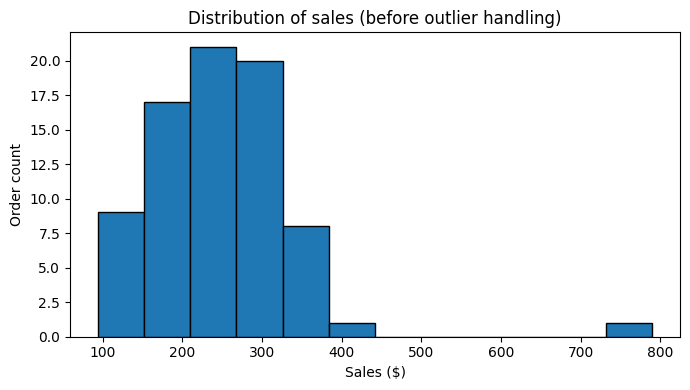

Insight: Most orders fall in a moderate sales range; a high observation stretches the right tail.


In [2]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df["sales"].dropna(), bins=12, edgecolor="black")
ax.set(title="Distribution of sales (before outlier handling)",xlabel="Sales ($)",ylabel="Order count")
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"01_sales_histogram.png",dpi=160); plt.show()
print("Insight: Most orders fall in a moderate sales range; a high observation stretches the right tail.")

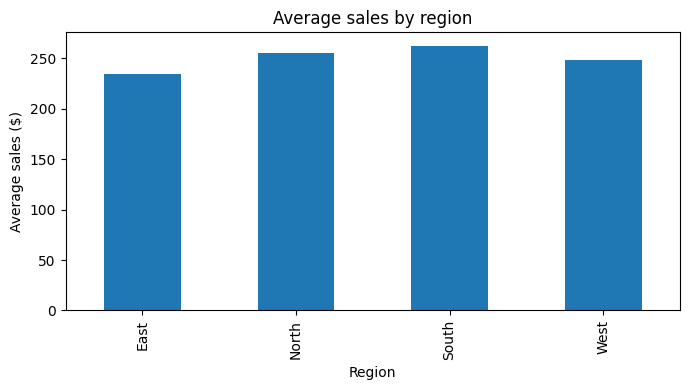

Insight: Regional means differ; these synthetic values do not establish a causal regional effect.


In [3]:
fig, ax = plt.subplots(figsize=(7,4))
df.groupby("region")["sales"].mean().sort_index().plot.bar(ax=ax)
ax.set(title="Average sales by region",xlabel="Region",ylabel="Average sales ($)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"02_region_bar.png",dpi=160); plt.show()
print("Insight: Regional means differ; these synthetic values do not establish a causal regional effect.")

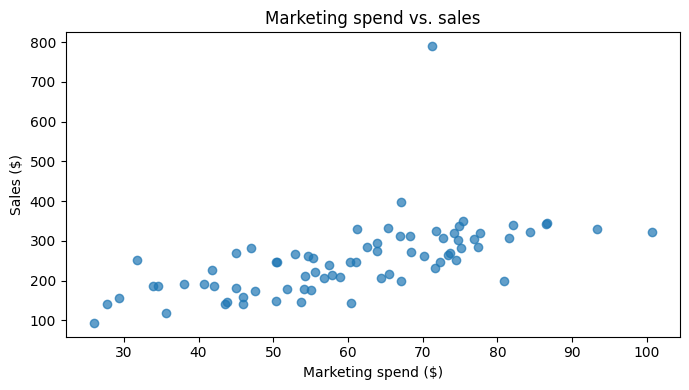

Insight: Inspecting the scatter plot helps identify possible association and unusual values.


In [4]:
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(df["marketing_spend"],df["sales"],alpha=.7)
ax.set(title="Marketing spend vs. sales",xlabel="Marketing spend ($)",ylabel="Sales ($)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"03_scatter.png",dpi=160); plt.show()
print("Insight: Inspecting the scatter plot helps identify possible association and unusual values.")

## Step 3 — Data preprocessing
### 3.1 Missing values
We count missing entries and replace missing numeric values with each column’s median. Median imputation is relatively resistant to extreme observations. The original data remains in `df`; cleaned values are in `clean`.

In [5]:
print("Missing values before cleaning:")
print(df.isna().sum())
clean = df.copy()
for col in ["sales","marketing_spend"]:
    clean[col] = clean[col].fillna(clean[col].median())
print("Missing values after median imputation:")
print(clean.isna().sum())
display(pd.concat({"Before":df.head(10),"After":clean.head(10)},axis=1))

Missing values before cleaning:
order_id           0
region             0
channel            0
sales              3
marketing_spend    2
units              0
dtype: int64
Missing values after median imputation:
order_id           0
region             0
channel            0
sales              0
marketing_spend    0
units              0
dtype: int64


Before                         ...   After                              
  order_id region channel   sales  ... channel   sales marketing_spend units
0        1  South   Store  159.96  ...   Store  159.96           46.01     8
1        2   East  Online   93.84  ...  Online   93.84           25.95    40
2        3   West   Store  147.13  ...   Store  147.13           53.65    16
3        4  North  Online  156.35  ...  Online  156.35           29.38    41
4        5  South   Store  117.99  ...   Store  117.99           35.64    60
5        6   East  Online  142.13  ...  Online  142.13           45.91    11
6        7   West   Store  141.50  ...   Store  141.50           43.50    38
7        8  North  Online  140.21  ...  Online  140.21           27.81    11
8        9  South   Store     NaN  ...   Store  246.55           36.64    64
9       10   East  Online  144.19  ...  Online  144.19           60.36    30

[10 rows x 12 columns]

### 3.2 Outlier detection with the IQR rule
Calculate Q1, Q3, IQR, and fences on the imputed sales values. Flag values outside the fences. For the cleaned analysis, cap outliers at the fences (winsorization) rather than dropping entire records.

Q1=190.47, Q3=302.96, IQR=112.48, lower=21.75, upper=471.68
Outlier count: 1


,order_id,sales
72,73,790.0


,order_id,sales,sales_adjusted
72,73,790.0,471.68125


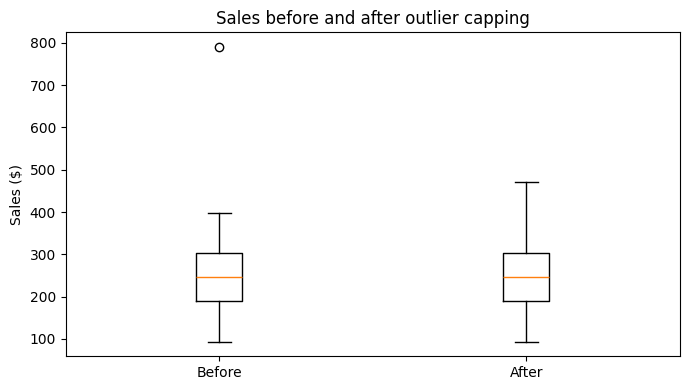

In [6]:
q1=clean["sales"].quantile(.25);q3=clean["sales"].quantile(.75);iqr=q3-q1
lower=q1-1.5*iqr;upper=q3+1.5*iqr
mask=(clean["sales"]<lower)|(clean["sales"]>upper)
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, lower={lower:.2f}, upper={upper:.2f}")
print("Outlier count:",int(mask.sum()))
display(clean.loc[mask,["order_id","sales"]])
clean["sales_adjusted"]=clean["sales"].clip(lower,upper)
display(clean.loc[mask,["order_id","sales","sales_adjusted"]])
fig,ax=plt.subplots(figsize=(7,4));ax.boxplot([clean["sales"],clean["sales_adjusted"]],tick_labels=["Before","After"]);ax.set(title="Sales before and after outlier capping",ylabel="Sales ($)");fig.tight_layout();fig.savefig(OUTPUT_DIR/"04_outliers_boxplot.png",dpi=160);plt.show()

### 3.3 Data reduction
Sample 50% of records reproducibly and drop `order_id` (an identifier that does not describe sales behavior) from the analytical feature set.

In [7]:
reduced=clean.sample(frac=.5,random_state=42).drop(columns=["order_id"])
print("Before reduction:",clean.shape,"After reduction:",reduced.shape)
display(reduced.head())

Before reduction: (80, 7) After reduction: (40, 6)


,region,channel,sales,marketing_spend,units,sales_adjusted
30,West,Store,227.81,41.78,57,227.81
0,South,Store,159.96,46.01,8,159.96
22,West,Store,185.97,42.03,55,185.97
31,North,Online,250.84,31.70,22,250.84
18,West,Store,178.75,51.79,42,178.75


### 3.4 Data scaling and discretization
Min–max scale adjusted sales to [0,1], calculate z-scores, and categorize adjusted sales into low, medium, and high quantile-based groups.

In [8]:
mn=clean["sales_adjusted"].min();mx=clean["sales_adjusted"].max()
clean["sales_minmax"]=(clean["sales_adjusted"]-mn)/(mx-mn)
clean["sales_zscore"]=(clean["sales_adjusted"]-clean["sales_adjusted"].mean())/clean["sales_adjusted"].std(ddof=0)
clean["sales_band"]=pd.qcut(clean["sales_adjusted"],q=3,labels=["Low","Medium","High"],duplicates="drop")
display(clean[["sales_adjusted","sales_minmax","sales_zscore","sales_band"]].head(10))
print("Min-max range:",clean["sales_minmax"].min(),clean["sales_minmax"].max())
print("Sales band counts:",clean["sales_band"].value_counts())

,sales_adjusted,sales_minmax,sales_zscore,sales_band
0,159.96,0.174994,-1.226021,Low
1,93.84,0.000000,-2.168078,Low
2,147.13,0.141038,-1.408819,Low
3,156.35,0.165440,-1.277455,Low
4,117.99,0.063916,-1.823996,Low
5,142.13,0.127805,-1.480057,Low
6,141.50,0.126138,-1.489033,Low
7,140.21,0.122723,-1.507413,Low
8,246.55,0.404164,0.007686,Medium
9,144.19,0.133257,-1.450707,Low


Min-max range: 0.0 1.0
Sales band counts: sales_band
Low       27
High      27
Medium    26
Name: count, dtype: int64


## Step 4 — Statistical analysis
### 4.1 Dataset overview (`info()` and `describe()`)

In [9]:
clean.info()
display(clean.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   order_id         80 non-null     int64   
 1   region           80 non-null     object  
 2   channel          80 non-null     object  
 3   sales            80 non-null     float64 
 4   marketing_spend  80 non-null     float64 
 5   units            80 non-null     int64   
 6   sales_adjusted   80 non-null     float64 
 7   sales_minmax     80 non-null     float64 
 8   sales_zscore     80 non-null     float64 
 9   sales_band       80 non-null     category
dtypes: category(1), float64(5), int64(2), object(2)
memory usage: 6.0+ KB


,order_id,region,channel,sales,marketing_spend,units,sales_adjusted,sales_minmax,sales_zscore,sales_band
count,80.0000,80,80,80.000000,80.000000,80.000000,80.000000,80.000000,8.000000e+01,80
unique,NaN,4,2,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,South,Store,NaN,NaN,NaN,NaN,NaN,NaN,Low
freq,NaN,20,40,NaN,NaN,NaN,NaN,NaN,NaN,27
mean,40.5000,NaN,NaN,249.989500,60.506500,34.487500,246.010516,0.402737,2.331468e-16,NaN
std,23.2379,NaN,NaN,89.854026,16.122257,16.276872,70.629649,0.186929,1.006309e+00,NaN
min,1.0000,NaN,NaN,93.840000,25.950000,8.000000,93.840000,0.000000,-2.168078e+00,NaN
25%,20.7500,NaN,NaN,190.475000,49.620000,21.750000,190.475000,0.255756,-7.912527e-01,NaN
50%,40.5000,NaN,NaN,246.550000,61.155000,35.000000,246.550000,0.404164,7.686405e-03,NaN
75%,60.2500,NaN,NaN,302.957500,73.072500,48.250000,302.957500,0.553453,8.113629e-01,NaN


### 4.2 Central tendency: minimum, maximum, mean, median, and mode

In [10]:
s=clean["sales_adjusted"]
central=pd.Series({"Minimum":s.min(),"Maximum":s.max(),"Mean":s.mean(),"Median":s.median(),"Mode (first)":s.mode().iloc[0]})
display(central.to_frame("Value"))

,Value
Minimum,93.840000
Maximum,471.681250
Mean,246.010516
Median,246.550000
Mode (first),246.550000


### 4.3 Dispersion: range, quartiles, IQR, sample variance, and sample standard deviation

In [11]:
dispersion=pd.Series({"Range":s.max()-s.min(),"Q1":s.quantile(.25),"Q3":s.quantile(.75),"IQR":s.quantile(.75)-s.quantile(.25),"Sample variance":s.var(ddof=1),"Sample std dev":s.std(ddof=1)})
display(dispersion.to_frame("Value"))

,Value
Range,377.841250
Q1,190.475000
Q3,302.957500
IQR,112.482500
Sample variance,4988.547346
Sample std dev,70.629649


### 4.4 Correlation matrix
Pearson correlation summarizes linear relationships; correlation does not imply causation.

,sales_adjusted,marketing_spend,units
sales_adjusted,1.000000,0.693366,0.105525
marketing_spend,0.693366,1.000000,0.064451
units,0.105525,0.064451,1.000000


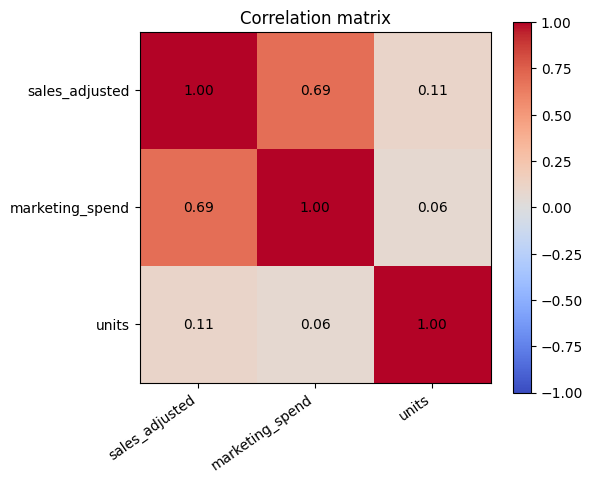

In [12]:
numeric_cols=["sales_adjusted","marketing_spend","units"]
corr=clean[numeric_cols].corr()
display(corr)
fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm");ax.set_xticks(range(len(numeric_cols)),numeric_cols,rotation=35,ha="right");ax.set_yticks(range(len(numeric_cols)),numeric_cols)
for i in range(len(numeric_cols)):
 for j in range(len(numeric_cols)):ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im,ax=ax);ax.set_title("Correlation matrix");fig.tight_layout();fig.savefig(OUTPUT_DIR/"05_correlation_matrix.png",dpi=160);plt.show()

## Conclusion and reflections
The notebook demonstrates data loading, exploratory charts, missing-value imputation, IQR-based outlier treatment, reproducible sampling, scaling, discretization, and descriptive statistics. Because the dataset is synthetic, results illustrate the methods rather than real retail performance. Median imputation retains rows but can suppress variability; capping outliers limits extreme influence but changes the distribution. Sampling saves work but reduces available observations. Visual and numerical checks should guide these choices.

**References:** pandas documentation (https://pandas.pydata.org/docs/), Matplotlib documentation (https://matplotlib.org/stable/), NumPy documentation (https://numpy.org/doc/).